In [1]:
import pandas as pd
df = pd.read_csv("churn.csv")

In [2]:
df.sample(60)

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
2118,5,0,39,0,305,6,7,2,2,1,2,25,45.495,1
1496,5,0,10,0,8448,157,55,33,4,1,1,45,352.625,0
1858,4,0,41,0,13468,169,1,43,3,1,1,30,549.480,0
691,2,0,26,0,1015,11,30,6,4,1,2,45,100.650,0
1653,5,0,35,0,3778,54,0,29,1,1,1,15,210.760,0
1301,0,0,43,0,273,9,15,8,2,1,2,25,80.190,0
1608,2,0,37,0,13583,169,25,46,3,1,1,30,650.080,0
2085,0,0,34,0,3413,76,0,26,2,1,1,25,157.005,0
408,5,0,35,0,13593,161,0,39,3,1,1,30,550.160,0
1399,0,0,3,0,0,0,0,0,2,1,1,25,0.000,1


<Axes: xlabel='Churn'>

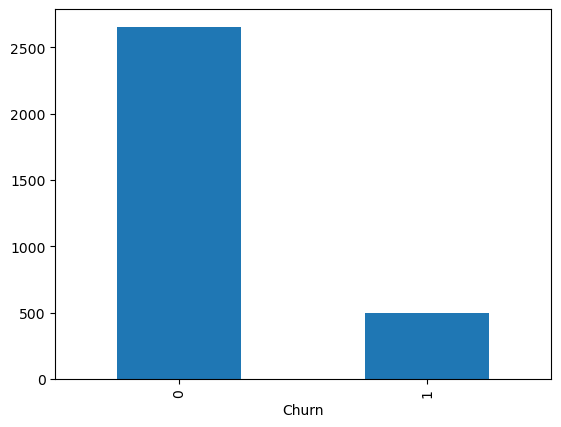

In [3]:
df.Churn.value_counts().plot(kind="bar")

In [4]:
df.isna().sum()

Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64

In [5]:
X = df.drop("Churn",axis="columns")
y = df["Churn"]

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report


In [10]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.3,random_state = 42)

model = LogisticRegression(max_iter = 2000)
model.fit(X_train,y_train)

y_pred = model.predict(X_test)
report = classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.89      0.97      0.93       783
           1       0.74      0.44      0.55       162

    accuracy                           0.88       945
   macro avg       0.82      0.70      0.74       945
weighted avg       0.87      0.88      0.86       945



C:\Users\Utkarsh\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [18]:
from imblearn.under_sampling import RandomUnderSampler
rus = RandomUnderSampler(random_state = 42)
X_train_rus,y_train_rus =  rus.fit_resample(X_train,y_train)
y_train_rus.value_counts()

Churn
0    333
1    333
Name: count, dtype: int64

In [20]:
model.fit(X_train_rus,y_train_rus)
y_pred_rus = model.predict(X_test)
report = classification_report(y_test,y_pred_rus)
print(report)

              precision    recall  f1-score   support

           0       0.96      0.82      0.89       783
           1       0.49      0.83      0.62       162

    accuracy                           0.83       945
   macro avg       0.73      0.83      0.75       945
weighted avg       0.88      0.83      0.84       945



C:\Users\Utkarsh\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [23]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state = 42)
X_train_sm,y_train_sm = smote.fit_resample(X_train,y_train)
y_train_sm.value_counts()

Churn
0    1872
1    1872
Name: count, dtype: int64

In [24]:
model.fit(X_train_sm,y_train_sm)
y_pred_sm = model.predict(X_test)
report = classification_report(y_test,y_pred_sm)
print(report)

              precision    recall  f1-score   support

           0       0.96      0.81      0.88       783
           1       0.48      0.84      0.61       162

    accuracy                           0.82       945
   macro avg       0.72      0.83      0.75       945
weighted avg       0.88      0.82      0.84       945



C:\Users\Utkarsh\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [28]:
from imblearn.combine import SMOTETomek
smote_tom = SMOTETomek(random_state=42)
X_trainst,y_trainst=smote_tom.fit_resample(X_train,y_train)


In [29]:
model.fit(X_trainst,y_trainst)
y_predst = model.predict(X_test)
report = classification_report(y_test,y_predst)
print(report)

              precision    recall  f1-score   support

           0       0.96      0.81      0.88       783
           1       0.49      0.85      0.62       162

    accuracy                           0.82       945
   macro avg       0.72      0.83      0.75       945
weighted avg       0.88      0.82      0.84       945



C:\Users\Utkarsh\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
